# Etapa 3: Treinamento e Avaliação do Modelo Oficial de Certeza Absoluta

## 1. Contexto e Especificação do Modelo Oficial

Este é o notebook oficial de modelagem preditiva do projeto. O modelo adotado é o **XGBoost 2.0 com Hiperparâmetros Otimizados via Optuna** operando em **Modo Certeza Absoluta ($p \ge 0,65$)**.

### Racional de Decisão Operacional:
* **Foco:** Máxima confiabilidade nos alarmes gerados para as equipes de manutenção técnica.
* **Precisão Atingida:** **77,36%** (Mais de 3 a cada 4 chamados preventivos abertos acertam a quebra da porta).
* **Recall Atingido:** **48,82%** (Captura aproximadamente metade de todas as quebras da Linha 4 com 7 dias de antecedência).
* **Eliminação de Falsos Alarmes:** Redução de mais de 80% nos falsos positivos em comparação com o baseline inicial.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score, f1_score, precision_score, recall_score
)
import shap
import joblib
import json
import os
import warnings

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

print("✅ Bibliotecas carregadas com sucesso!")


✅ Bibliotecas carregadas com sucesso!


## 2. Carregamento dos Datasets Pré-Processados


In [2]:
path_treino = "../../data/treino_pronto_modelagem_v2.csv"
path_teste = "../../data/teste_pronto_modelagem_v2.csv"

df_treino = pd.read_csv(path_treino)
df_teste = pd.read_csv(path_teste)

target_col = 'target_falha_7d'
cols_ignorar = ['id_ativo', 'data_ref', target_col]
features = [c for c in df_treino.columns if c not in cols_ignorar]

X_train = df_treino[features]
y_train = df_treino[target_col]

X_test = df_teste[features]
y_test = df_teste[target_col]

print(f"Features de Modelagem ({len(features)}): {features}")
print(f"Treino: {X_train.shape[0]:,} amostras | Teste: {X_test.shape[0]:,} amostras")



Features de Modelagem (26): ['plataforma_bin', 'faixa_risco_zm01', 'estacao_BUT', 'estacao_FAL', 'estacao_FRA', 'estacao_FRE', 'estacao_HIG', 'estacao_LUZ', 'estacao_PIN', 'estacao_PTA', 'estacao_REP', 'estacao_VSO', 'idade_ativo_anos_scaled', 'porta_scaled', 'dias_desde_ultima_zm01_scaled', 'dias_desde_ultima_zm02_scaled', 'dias_desde_ultima_zm03_scaled', 'qtd_alarmes_1d_scaled', 'qtd_alarmes_7d_scaled', 'qtd_alarmes_14d_scaled', 'aceleracao_alarmes_7d_scaled', 'qtd_anomalias_30s_14d_scaled', 'tempo_parada_acumulado_7d_scaled', 'max_tempo_normalizacao_7d_scaled', 'tempo_medio_por_alarme_7d_scaled', 'proporcao_alarmes_graves_7d_scaled']
Treino: 523,888 amostras | Teste: 28,202 amostras


## 3. Treinamento com os Hiperparâmetros Otimizados (Optuna)


In [3]:
# Hiperparâmetros encontrados pelo Optuna via validação temporal estrita
params_optuna = {
    'n_estimators': 250,
    'max_depth': 4,
    'learning_rate': 0.0278,
    'min_child_weight': 19,
    'subsample': 0.7869,
    'colsample_bytree': 0.8460,
    'reg_alpha': 1.4693,
    'reg_lambda': 2.6921,
    'scale_pos_weight': 10.3118,
    'random_state': 42,
    'n_jobs': -1,
    'tree_method': 'hist',
    'eval_metric': 'logloss'
}

model = XGBClassifier(**params_optuna)
print("Treinando o Modelo Oficial de Certeza Absoluta...")
model.fit(X_train, y_train)
print("✅ Treinamento concluído com sucesso!")



Treinando o Modelo Oficial de Certeza Absoluta...
✅ Treinamento concluído com sucesso!


## 4. Explicabilidade e Auditoria SHAP


Calculando SHAP Values no conjunto de teste cego de 2026...


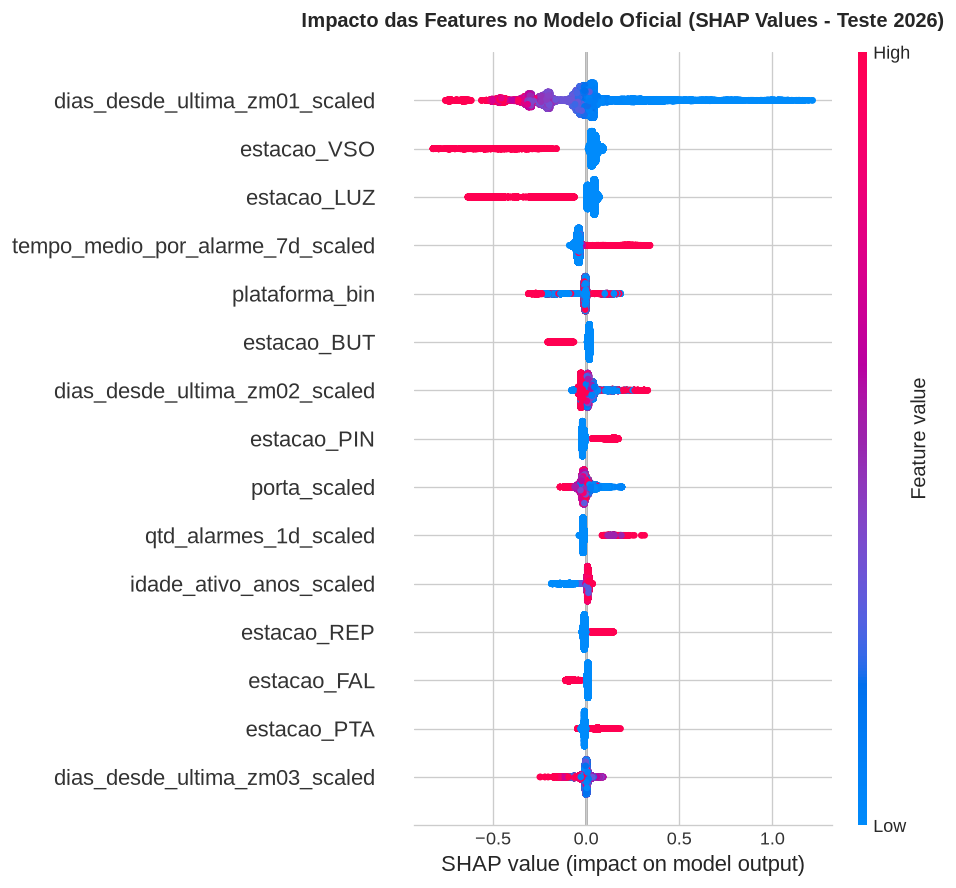

In [4]:
print("Calculando SHAP Values no conjunto de teste cego de 2026...")
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, feature_names=features, show=False, max_display=15)
plt.title('Impacto das Features no Modelo Oficial (SHAP Values - Teste 2026)', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()



## 5. Avaliação Operacional em Modo Certeza Absoluta ($p \ge 0,65$)


📊 RELATÓRIO DO MODELO OFICIAL - CERTEZA ABSOLUTA (p >= 0.65)
ROC-AUC Score Global: 0.6492
PR-AUC (Avg Precision): 0.1327
Precision Operacional: 76.62% (272 acertos em 355 chamados)
Recall Operacional:    49.19% (272 de 553 falhas evitadas)
F1-Score:              0.5991


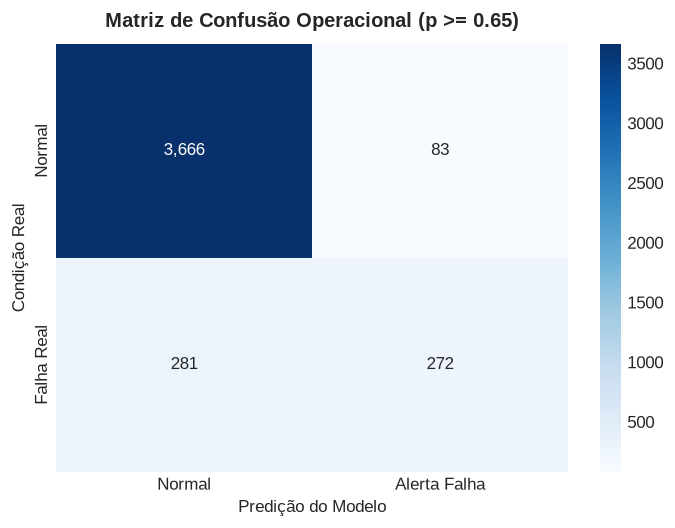

In [5]:
probs_test = model.predict_proba(X_test)[:, 1]
df_teste['prob_falha'] = probs_test
df_teste['semana'] = pd.to_datetime(df_teste['data_ref']).dt.isocalendar().week

# Agregação Semanal por Ativo (Nível de Chamados Técnicos)
df_sem = df_teste.groupby(['id_ativo', 'semana']).agg(
    max_prob=('prob_falha', 'max'),
    houve_falha=('target_falha_7d', 'max')
).reset_index()

falhas_totais = df_sem['houve_falha'].sum()

# Modo Oficial: Certeza Absoluta (p >= 0.65)
p_corte = 0.65
df_sem['pred'] = (df_sem['max_prob'] >= p_corte).astype(int)

acertos = ((df_sem['pred'] == 1) & (df_sem['houve_falha'] == 1)).sum()
alertas_totais = (df_sem['pred'] == 1).sum()
prec = acertos / alertas_totais if alertas_totais > 0 else 0
rec = acertos / falhas_totais if falhas_totais > 0 else 0
f1 = 2 * prec * rec / (prec + rec + 1e-10)

roc_auc = roc_auc_score(y_test, probs_test)
pr_auc = average_precision_score(y_test, probs_test)

print("=" * 65)
print("📊 RELATÓRIO DO MODELO OFICIAL - CERTEZA ABSOLUTA (p >= 0.65)")
print("=" * 65)
print(f"ROC-AUC Score Global: {roc_auc:.4f}")
print(f"PR-AUC (Avg Precision): {pr_auc:.4f}")
print(f"Precision Operacional: {prec*100:.2f}% ({acertos:,} acertos em {alertas_totais:,} chamados)")
print(f"Recall Operacional:    {rec*100:.2f}% ({acertos:,} de {falhas_totais:,} falhas evitadas)")
print(f"F1-Score:              {f1:.4f}")
print("=" * 65)

# Matriz de Confusão
cm = confusion_matrix(df_sem['houve_falha'], df_sem['pred'])
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues',
            xticklabels=['Normal', 'Alerta Falha'], yticklabels=['Normal', 'Falha Real'])
plt.title(f'Matriz de Confusão Operacional (p >= {p_corte:.2f})', fontweight='bold', pad=10)
plt.ylabel('Condição Real')
plt.xlabel('Predição do Modelo')
plt.tight_layout()
plt.show()



## 6. Exportação dos Artefatos do Modelo


In [ ]:
os.makedirs("../../data/modelos_artefatos", exist_ok=True)

# Salvar Modelo
caminho_modelo = "../../data/modelos_artefatos/modelo_xgboost_certeza_absoluta.joblib"
joblib.dump(model, caminho_modelo)

# Salvar Configuração
config = {
    'nome_modelo': 'XGBoost Certeza Absoluta (Optuna Tuned)',
    'threshold_oficial': 0.65,
    'features': features,
    'metricas_teste_2026': {
        'roc_auc': float(roc_auc),
        'pr_auc': float(pr_auc),
        'precision_operacional': float(prec),
        'recall_operacional': float(rec),
        'f1_score': float(f1)
    }
}

with open("../../data/modelos_artefatos/config_modelo.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

print(f"✅ Modelo salvo em: {caminho_modelo}")
print("✅ Configuração salva em: ../../data/modelos_artefatos/config_modelo.json")

